# Link communities — *Os Maias*

This notebook implements the link-clustering method of Ahn, Bagrow and Lehmann (2010). Unlike node-based methods, it clusters **edges**. A character can therefore belong to several communities when different subsets of their relationships connect them to different social contexts.

For two links sharing a character, `(i,k)` and `(j,k)`, similarity is the Jaccard overlap of the **inclusive neighborhoods** of their non-shared endpoints:

\[
S_{(i,k),(j,k)} =
\frac{|n_+(i)\cap n_+(j)|}{|n_+(i)\cup n_+(j)|}.
\]

Adjacent links are merged by descending similarity (single linkage). The selected cut maximizes partition density:

\[
D = \frac{2}{M}\sum_c
\frac{m_c\,[m_c-(n_c-1)]}{(n_c-2)(n_c-1)},
\]

where `m_c` and `n_c` are the number of links and characters in link community `c`, and `M` is the total number of links. Communities with fewer than three links are retained in the full dendrogram but excluded from the reported character memberships.

The co-occurrence weight is used to define thresholded graphs. Within each thresholded graph, link similarity and partition density are topological (unweighted), matching the previous notebook's stated design.

## 1. Load the weighted graph and define settings

In [1]:
from pathlib import Path
from itertools import combinations
from collections import defaultdict
import math
import warnings

import networkx as nx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Locate the project data without assuming the notebook's working directory.
ROOT_CANDIDATES = [Path.cwd(), *Path.cwd().parents]
def find_data_file(filename):
    candidates = []
    for root in ROOT_CANDIDATES:
        candidates += [
            root / "Data" / filename,
            root / "data" / filename,
            root / filename,
        ]
    for path in candidates:
        if path.exists():
            return path
    return None

EDGE_PATH = find_data_file("os_maias_cooccurrence_edges.csv")
NODE_PATH = find_data_file("os_maias_ground_truth_nodes.csv")

if EDGE_PATH is None:
    raise FileNotFoundError(
        "Could not find Data/os_maias_cooccurrence_edges.csv. "
        "Place the Os Maias edge CSV in a Data/ or data/ folder next to the project."
    )

def load_weighted_graph(edge_path=EDGE_PATH, node_path=NODE_PATH):
    edges = pd.read_csv(edge_path, dtype={"source": str, "target": str})
    required = {"source", "target", "weight"}
    if not required.issubset(edges.columns):
        raise ValueError(f"Edge file must contain columns {sorted(required)}")
    G = nx.Graph()
    for row in edges.itertuples(index=False):
        u, v, w = str(row.source).strip(), str(row.target).strip(), float(row.weight)
        if u == v or not np.isfinite(w) or w <= 0:
            continue
        if G.has_edge(u, v):
            G[u][v]["weight"] += w
        else:
            G.add_edge(u, v, weight=w)

    names = {}
    if node_path is not None and node_path.exists():
        nodes = pd.read_csv(node_path, dtype=str)
        if {"id", "name"}.issubset(nodes.columns):
            for node_id, name in zip(nodes["id"].str.strip(), nodes["name"]):
                G.add_node(node_id)
                if pd.notna(name) and str(name).strip():
                    names[node_id] = str(name).strip()
    for node in G:
        names.setdefault(node, str(node).replace("_", " ").title())
    return G, names

def threshold_graph(G, w_min):
    H = nx.Graph()
    H.add_nodes_from(G.nodes(data=True))
    H.add_edges_from(
        (u, v, dict(d)) for u, v, d in G.edges(data=True)
        if float(d.get("weight", 1.0)) >= w_min
    )
    return H

def transformed_weights(G, mode="log"):
    strength = dict(G.degree(weight="weight"))
    out = {}
    for u, v, d in G.edges(data=True):
        w = float(d.get("weight", 1.0))
        if mode == "raw":
            value = w
        elif mode == "log":
            value = np.log1p(w)
        elif mode == "sqrt":
            value = np.sqrt(w)
        elif mode == "cosine":
            value = w / np.sqrt(strength[u] * strength[v])
        elif mode == "none":
            value = 1.0
        else:
            raise ValueError("mode must be raw, log, sqrt, cosine or none")
        out[tuple(sorted((u, v)))] = float(value)
    return out

def with_transformed_weights(G, mode="log", attr="tw"):
    H = G.copy()
    weights = transformed_weights(G, mode)
    for u, v in H.edges:
        H[u][v][attr] = weights[tuple(sorted((u, v)))]
    return H

def cover_summary(G, cover):
    groups = [set(c) for c in cover if c]
    memberships = defaultdict(int)
    for c in groups:
        for node in c:
            memberships[node] += 1
    covered = set(memberships)
    sizes = sorted((len(c) for c in groups), reverse=True)
    return {
        "communities": len(groups),
        "coverage_pct": 100 * len(covered) / G.number_of_nodes() if G.number_of_nodes() else 0,
        "overlap_nodes": sum(v > 1 for v in memberships.values()),
        "mean_memberships": float(np.mean(list(memberships.values()))) if memberships else 0.0,
        "largest_size": sizes[0] if sizes else 0,
        "giant_fraction": sizes[0] / len(covered) if covered else 0.0,
    }

def overlapping_modularity(G, cover, weight="tw"):
    total_weight = G.size(weight=weight)
    if total_weight <= 0:
        return 0.0
    strength = dict(G.degree(weight=weight))
    memberships = defaultdict(int)
    groups = [set(c) for c in cover if c]
    for c in groups:
        for node in c:
            memberships[node] += 1
    two_w = 2 * total_weight
    eq = 0.0
    for c in groups:
        for i in c:
            for j in c:
                aij = G[i][j].get(weight, 1.0) if G.has_edge(i, j) else 0.0
                eq += (aij - strength[i] * strength[j] / two_w) / (
                    memberships[i] * memberships[j]
                )
    return float(eq / two_w)

def louvain_reference(G, seeds=(41, 42, 43, 44, 45), weight="tw"):
    return [
        [set(c) for c in nx.community.louvain_communities(G, weight=weight, seed=s)]
        for s in seeds
    ]

def _binary_entropy(p):
    if p <= 0 or p >= 1:
        return 0.0
    return float(-p*np.log2(p) - (1-p)*np.log2(1-p))

def _conditional_entropy_norm(x_cover, y_cover, n):
    vals = []
    for x in x_cover:
        hx = _binary_entropy(len(x)/n)
        if hx == 0:
            continue
        best = hx
        for y in y_cover:
            p11 = len(x & y)/n
            p10 = (len(x)-len(x&y))/n
            p01 = (len(y)-len(x&y))/n
            p00 = 1-p11-p10-p01
            if _binary_entropy(p11)+_binary_entropy(p00) <= _binary_entropy(p01)+_binary_entropy(p10):
                continue
            h_joint = -sum(p*np.log2(p) for p in (p11,p10,p01,p00) if p > 0)
            best = min(best, h_joint - _binary_entropy(len(y)/n))
        vals.append(best/hx)
    return float(np.mean(vals)) if vals else 1.0

def overlapping_nmi(cover_a, cover_b, nodes):
    universe = list(nodes)
    n = len(universe)
    if n == 0 or not cover_a or not cover_b:
        return 0.0
    a = [set(c) & set(universe) for c in cover_a if c]
    b = [set(c) & set(universe) for c in cover_b if c]
    value = 1 - 0.5*(_conditional_entropy_norm(a,b,n)+_conditional_entropy_norm(b,a,n))
    return float(np.clip(value, 0, 1))

def mean_onmi_to_louvain(cover, G, runs):
    nodes = [n for n in G if G.degree(n) > 0]
    return float(np.mean([overlapping_nmi(cover, r, nodes) for r in runs])) if runs else np.nan

G, name_map = load_weighted_graph()
print({
    "edge_file": str(EDGE_PATH),
    "node_file": str(NODE_PATH) if NODE_PATH else "not found (all edge endpoints retained)",
    "nodes": G.number_of_nodes(),
    "edges": G.number_of_edges(),
    "density": nx.density(G),
    "weight_range": (min((d["weight"] for _,_,d in G.edges(data=True)), default=0),
                     max((d["weight"] for _,_,d in G.edges(data=True)), default=0)),
})
display(pd.DataFrame([{
    "nodes": G.number_of_nodes(), "edges": G.number_of_edges(),
    "density": nx.density(G), "components": nx.number_connected_components(G),
    "isolates": nx.number_of_isolates(G)
}]))

{'edge_file': 'c:\\Users\\lenovo\\OneDrive\\Documentos\\Uni\\DTU - Master in Business Analytics\\Social Graphs\\SGI-Project\\Data\\os_maias_cooccurrence_edges.csv', 'node_file': 'c:\\Users\\lenovo\\OneDrive\\Documentos\\Uni\\DTU - Master in Business Analytics\\Social Graphs\\SGI-Project\\Data\\os_maias_ground_truth_nodes.csv', 'nodes': 103, 'edges': 663, 'density': 0.1262135922330097, 'weight_range': (1.0, 515.0)}


,nodes,edges,density,components,isolates
0,103,663,0.126214,1,0


## 2. Implement link similarity, hierarchical clustering and partition density

In [2]:
def inclusive_neighborhoods(G):
    return {u: set(G.neighbors(u)) | {u} for u in G}


def link_similarity(G, link_a, link_b, neighborhoods=None):
    """Jaccard similarity of inclusive neighborhoods of non-shared endpoints."""
    u, v = link_a
    x, y = link_b
    shared = set((u, v)) & set((x, y))
    if len(shared) != 1:
        return None
    hub = next(iter(shared))
    other_a = v if u == hub else u
    other_b = y if x == hub else x
    neighborhoods = neighborhoods or inclusive_neighborhoods(G)
    a, b = neighborhoods[other_a], neighborhoods[other_b]
    union = a | b
    return len(a & b) / len(union) if union else 0.0


def partition_density(link_groups, M):
    """Ahn–Bagrow–Lehmann partition density for a partition of M links."""
    if M == 0:
        return 0.0
    total = 0.0
    for group in link_groups:
        m_c = len(group)
        nodes = {node for edge in group for node in edge}
        n_c = len(nodes)
        if n_c > 2:
            total += m_c * (m_c - (n_c - 1)) / ((n_c - 2) * (n_c - 1))
    return float(2.0 * total / M)


def build_link_dendrogram(links, merge_log):
    """Build a binary merge forest with the local D contribution of every branch."""
    nodes, parents = {}, {}
    for link_id, link in enumerate(links):
        nodes[link_id] = {
            "children": None,
            "link_ids": frozenset({link_id}),
            "node_set": frozenset(link),
            "partition_contribution": 0.0,
            "similarity": np.nan,
        }

    for row in merge_log.itertuples(index=False):
        left, right, merged = int(row.left_cluster), int(row.right_cluster), int(row.merged_cluster)
        link_ids = nodes[left]["link_ids"] | nodes[right]["link_ids"]
        node_set = nodes[left]["node_set"] | nodes[right]["node_set"]
        m_c, n_c = len(link_ids), len(node_set)
        contribution = (
            m_c * (m_c - (n_c - 1)) / ((n_c - 2) * (n_c - 1))
            if n_c > 2 else 0.0
        )
        nodes[merged] = {
            "children": (left, right),
            "link_ids": frozenset(link_ids),
            "node_set": frozenset(node_set),
            "partition_contribution": contribution,
            "similarity": float(row.similarity),
        }
        parents[left] = merged
        parents[right] = merged
    return {"nodes": nodes, "parent": parents, "roots": sorted(set(nodes) - set(parents))}


def _membership_from_groups(groups):
    membership = defaultdict(set)
    for community_id, group in enumerate(groups, start=1):
        for node in {node for edge in group for node in edge}:
            membership[node].add(community_id)
    return {node: sorted(ids) for node, ids in membership.items()}


def result_for_cut(result, cut_nodes):
    """Translate a valid branch cut into the notebook's regular result format."""
    tree = result["dendrogram"]["nodes"]
    links = result["links"]
    all_groups = [
        {links[link_id] for link_id in tree[node_id]["link_ids"]}
        for node_id in cut_nodes
    ]
    all_groups = sorted(all_groups, key=lambda group: (-len(group), tuple(sorted(group))))
    reported = [group for group in all_groups if len(group) >= result["min_community_links"]]
    return {
        **result,
        "all_groups": all_groups,
        "communities": reported,
        "membership": _membership_from_groups(reported),
        "best_D": partition_density(all_groups, len(links)),
        "best_similarity": np.nan,
        "best_cut_nodes": tuple(sorted(cut_nodes)),
    }


def link_communities(G, min_community_links=3):
    """Single-linkage link communities, the best global D cut, and its tree."""
    links = sorted(tuple(sorted(edge)) for edge in G.edges())
    M = len(links)
    empty_merge_log = pd.DataFrame(
        columns=["similarity", "left_cluster", "right_cluster", "merged_cluster"]
    )
    if M == 0:
        return {
            "links": [], "similarities": pd.DataFrame(), "merges": empty_merge_log,
            "density_curve": pd.DataFrame(), "all_groups": [], "communities": [],
            "best_D": 0.0, "best_similarity": np.nan, "membership": {},
            "best_cut_nodes": (), "dendrogram": {"nodes": {}, "parent": {}, "roots": []},
            "min_community_links": min_community_links,
        }

    neighborhoods = inclusive_neighborhoods(G)
    incident = defaultdict(list)
    for index, (u, v) in enumerate(links):
        incident[u].append(index)
        incident[v].append(index)

    similarities = {}
    for ids in incident.values():
        for left, right in combinations(ids, 2):
            pair = (min(left, right), max(left, right))
            similarity = link_similarity(G, links[left], links[right], neighborhoods)
            similarities[pair] = max(similarities.get(pair, -1.0), similarity)
    sim_df = pd.DataFrame(
        [{"link_i": left, "link_j": right, "similarity": similarity}
         for (left, right), similarity in similarities.items()]
    )

    parent = list(range(M))
    rank = [0] * M
    cluster_id = list(range(M))
    merge_rows, curve_rows = [], []

    def find(index):
        while parent[index] != index:
            parent[index] = parent[parent[index]]
            index = parent[index]
        return index

    def union(left, right, similarity):
        left_root, right_root = find(left), find(right)
        if left_root == right_root:
            return False
        left_cluster, right_cluster = cluster_id[left_root], cluster_id[right_root]
        if rank[left_root] < rank[right_root]:
            left_root, right_root = right_root, left_root
        parent[right_root] = left_root
        if rank[left_root] == rank[right_root]:
            rank[left_root] += 1
        merged_cluster = M + len(merge_rows)
        cluster_id[left_root] = merged_cluster
        merge_rows.append({
            "similarity": similarity,
            "left_cluster": left_cluster,
            "right_cluster": right_cluster,
            "merged_cluster": merged_cluster,
        })
        return True

    ordered_pairs = sorted(
        [(similarity, left, right) for (left, right), similarity in similarities.items()],
        key=lambda row: (-row[0], row[1], row[2]),
    )
    best_D, best_similarity = 0.0, np.nan
    best_groups = [{edge} for edge in links]
    best_cut_nodes = list(range(M))
    cursor = 0
    while cursor < len(ordered_pairs):
        similarity = ordered_pairs[cursor][0]
        batch = []
        while cursor < len(ordered_pairs) and np.isclose(ordered_pairs[cursor][0], similarity):
            batch.append(ordered_pairs[cursor])
            cursor += 1
        for _, left, right in batch:
            union(left, right, similarity)
        groups_by_root = defaultdict(set)
        for index in range(M):
            groups_by_root[find(index)].add(index)
        all_groups = [{links[index] for index in group} for group in groups_by_root.values()]
        density = partition_density(all_groups, M)
        curve_rows.append({
            "similarity": similarity,
            "partition_density": density,
            "link_clusters": len(all_groups),
        })
        if density > best_D + 1e-12:
            best_D, best_similarity = density, similarity
            best_groups = all_groups
            best_cut_nodes = sorted({cluster_id[find(index)] for index in range(M)})

    merge_log = pd.DataFrame(merge_rows, columns=empty_merge_log.columns)
    best_groups = sorted(best_groups, key=lambda group: (-len(group), tuple(sorted(group))))
    reported = [group for group in best_groups if len(group) >= min_community_links]
    return {
        "links": links,
        "similarities": sim_df,
        "merges": merge_log,
        "density_curve": pd.DataFrame(curve_rows),
        "all_groups": best_groups,
        "communities": reported,
        "best_D": best_D,
        "best_similarity": best_similarity,
        "membership": _membership_from_groups(reported),
        "best_cut_nodes": tuple(best_cut_nodes),
        "dendrogram": build_link_dendrogram(links, merge_log),
        "min_community_links": min_community_links,
    }


def _adaptive_temperature(n_links, hard_density):
    factor = 0.3 if hard_density > 0.7 else 0.01 if hard_density < 0.01 else 1.0
    return float(np.clip(0.1 * factor / max(n_links, 1), 1e-8, 1e-3))


def run_adaptive_walk(result, seed=2026, n_steps=5000):
    """Metropolis–Hastings branch-cut search with logarithmic cooling."""
    if not result["links"]:
        return {"best_partition": result, "best_D": 0.0, "seed": seed,
                "n_steps": 0, "n_accepted": 0, "n_proposed": 0, "acceptance_rate": 0.0}

    n_links = len(result["links"])
    tree, nodes = result["dendrogram"], result["dendrogram"]["nodes"]
    parents = tree["parent"]
    temperature = _adaptive_temperature(n_links, result["best_D"])
    cooling_start = int(2 * n_steps / 3)
    rng = np.random.default_rng(seed)
    current = set(result["best_cut_nodes"])
    current_list = sorted(current)
    current_contribution = sum(nodes[node]["partition_contribution"] for node in current)
    best, best_density = set(current), 2.0 * current_contribution / n_links
    accepted = proposed = 0

    for step in range(n_steps):
        selected = current_list[int(rng.integers(len(current_list)))]
        children = nodes[selected]["children"]
        actions = ([] if selected not in parents else ["up"]) + ([] if children is None else ["down"])
        if not actions:
            continue
        proposed += 1
        action = actions[int(rng.integers(len(actions)))]
        if action == "down":
            left, right = children
            proposal = (current - {selected}) | {left, right}
            delta = nodes[left]["partition_contribution"] + nodes[right]["partition_contribution"] - nodes[selected]["partition_contribution"]
        else:
            parent_node = parents[selected]
            parent_links = nodes[parent_node]["link_ids"]
            removed = [node for node in current if nodes[node]["link_ids"] <= parent_links]
            proposal = (current - set(removed)) | {parent_node}
            delta = nodes[parent_node]["partition_contribution"] - sum(nodes[node]["partition_contribution"] for node in removed)

        delta_density = 2.0 * delta / n_links
        current_temperature = temperature if step <= cooling_start else temperature / np.log(step - cooling_start + 2)
        if delta_density >= 0 or rng.random() < np.exp(delta_density / current_temperature):
            current, current_contribution = proposal, current_contribution + delta
            if action == "down":
                current_list.remove(selected)
                current_list.extend((left, right))
            else:
                removed_set = set(removed)
                current_list = [node for node in current_list if node not in removed_set]
                current_list.append(parent_node)
            accepted += 1
            density = 2.0 * current_contribution / n_links
            if density > best_density + 1e-14:
                best, best_density = set(current), density

    best_partition = result_for_cut(result, best)
    return {
        "best_partition": best_partition,
        "best_D": best_partition["best_D"],
        "seed": seed,
        "n_steps": n_steps,
        "n_accepted": accepted,
        "n_proposed": proposed,
        "acceptance_rate": accepted / proposed if proposed else 0.0,
        "temperature": temperature,
        "cooling_start": cooling_start,
    }


def summarize_link_result(G, result, names, w_min):
    links = result["links"]
    M = len(links)
    groups = result["communities"]
    covered_links = sum(len(group) for group in groups)
    node_sets = [{node for edge in group for node in edge} for group in groups]
    covered_nodes = set().union(*node_sets) if node_sets else set()
    membership = defaultdict(int)
    for group in node_sets:
        for node in group:
            membership[node] += 1
    sizes = sorted((len(group) for group in groups), reverse=True)
    return {
        "w_min": w_min,
        "links": M,
        "link_communities": len(groups),
        "D_star": result["best_D"],
        "best_similarity": result["best_similarity"],
        "links_in_reported_communities_pct": 100 * covered_links / M if M else 0,
        "covered_characters": len(covered_nodes),
        "overlap_characters": sum(value > 1 for value in membership.values()),
        "largest_community_link_fraction": sizes[0] / M if sizes and M else 0,
        "small_clusters": len(result["all_groups"]) - len(groups),
    }


def link_membership_table(result, names):
    rows = []
    for community_id, group in enumerate(result["communities"], start=1):
        nodes = sorted({node for edge in group for node in edge}, key=lambda node: names.get(node, node).casefold())
        for node in nodes:
            rows.append({
                "community": community_id,
                "character_id": node,
                "character": names.get(node, node),
                "is_overlap": len(result["membership"].get(node, [])) > 1,
                "degree_in_threshold_graph": None,
            })
    return pd.DataFrame(rows)


def link_community_summary(result, names):
    rows = []
    for community_id, group in enumerate(result["communities"], start=1):
        nodes = sorted({node for edge in group for node in edge}, key=lambda node: names.get(node, node).casefold())
        rows.append({
            "community": community_id,
            "links": len(group),
            "characters": len(nodes),
            "members": ", ".join(names.get(node, node) for node in nodes),
        })
    return pd.DataFrame(rows).sort_values("links", ascending=False) if rows else pd.DataFrame(
        columns=["community", "links", "characters", "members"]
    )


## 3. Validate the implementation on a small graph

This toy graph contains a triangle with a tail. The code checks that the link partition is valid and that the partition-density calculation is finite.

In [3]:
toy = nx.Graph()
toy.add_edges_from([(0,1),(1,2),(2,0),(2,3),(3,4)])
toy_result = link_communities(toy, min_community_links=1)
assert len(toy_result["links"]) == toy.number_of_edges()
assert np.isfinite(toy_result["best_D"])
# Every original link is assigned to exactly one component at the selected cut.
flattened = [e for group in toy_result["all_groups"] for e in group]
assert sorted(flattened) == sorted(tuple(sorted(e)) for e in toy.edges())
print("Toy graph D*:", round(toy_result["best_D"], 4))
print("Reported link communities:", [len(c) for c in toy_result["communities"]])

Toy graph D*: 0.6
Reported link communities: [3, 1, 1]


## 4. Run the method across edge-weight thresholds

The previous analysis used thresholds 1, 2 and 3. These are kept as the default comparison. Each threshold is a separate graph: nodes are retained, while only edges with weight at least `w_min` are included.

In [4]:
THRESHOLDS = (1, 2, 3)
MIN_COMMUNITY_LINKS = 3

results = {}
summary_rows = []
for w_min in THRESHOLDS:
    H = threshold_graph(G, w_min)
    result = link_communities(H, min_community_links=MIN_COMMUNITY_LINKS)
    results[w_min] = result
    summary_rows.append(summarize_link_result(H, result, name_map, w_min))

summary = pd.DataFrame(summary_rows)
display(summary.round(4))

,w_min,links,link_communities,D_star,best_similarity,links_in_reported_communities_pct,covered_characters,overlap_characters,largest_community_link_fraction,small_clusters
0,1,663,39,0.3342,0.4524,92.1569,93,57,0.4676,45
1,2,472,17,0.2725,0.3662,90.6780,76,31,0.6864,36
2,3,343,16,0.3394,0.4884,72.0117,42,30,0.3353,80


## 5. Inspect the partition-density curves

Each point represents the partition after all link-pairs at one similarity level have been merged. The selected cut is the maximum of `D`. Tied similarities are processed together so that the result does not depend on the arbitrary ordering of equal-similarity pairs.

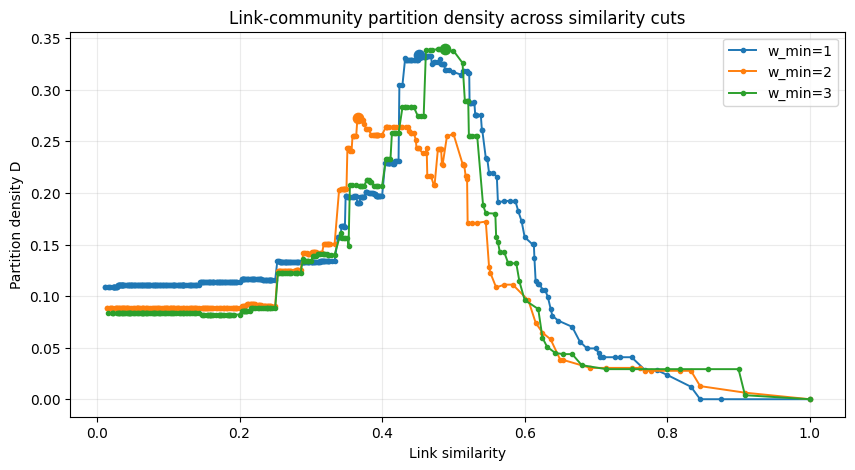

In [5]:
fig, ax = plt.subplots(figsize=(10,5))
for w_min, result in results.items():
    curve = result["density_curve"]
    if not curve.empty:
        ax.plot(curve["similarity"], curve["partition_density"],
                marker=".", linewidth=1.4, label=f"w_min={w_min}")
        ax.scatter([result["best_similarity"]], [result["best_D"]], s=55, zorder=3)
ax.set_xlabel("Link similarity")
ax.set_ylabel("Partition density D")
ax.set_title("Link-community partition density across similarity cuts")
ax.legend()
ax.grid(alpha=.25)
plt.show()

## 6. Select a threshold for detailed inspection

The selection below is a transparent heuristic, not a statistical proof. It prioritizes high partition density, reasonable link coverage, and avoids a single community swallowing most links. Change the criteria if the graph or research question calls for it.

In [6]:
MIN_LINK_COVERAGE_PCT = 40.0
MAX_GIANT_LINK_FRACTION = 0.70

eligible = summary[
    (summary["links_in_reported_communities_pct"] >= MIN_LINK_COVERAGE_PCT) &
    (summary["largest_community_link_fraction"] <= MAX_GIANT_LINK_FRACTION) &
    (summary["link_communities"] >= 2)
].copy()
if eligible.empty:
    print("No threshold meets every filter; selecting the maximum-D threshold for inspection.")
    eligible = summary.copy()
selected_row = eligible.sort_values(
    ["D_star","links_in_reported_communities_pct"], ascending=False
).iloc[0]
W_MIN = int(selected_row["w_min"])
H = threshold_graph(G, W_MIN)
result = results[W_MIN]
print(f"Selected w_min={W_MIN}; D*={result['best_D']:.4f}; "
      f"best similarity={result['best_similarity']:.4f}")

Selected w_min=3; D*=0.3394; best similarity=0.4884


## 7. Final hard cut — one global dendrogram height

This is the final conventional link-community result: one similarity height for the entire dendrogram, chosen where partition density is maximal. The first table is grouped by community and lists every character in each reported community; the long table makes character overlap explicit.


In [7]:
hard_community_summary = link_community_summary(result, name_map)
hard_membership = link_membership_table(result, name_map)
degree_map = dict(H.degree())
if not hard_membership.empty:
    hard_membership["degree_in_threshold_graph"] = hard_membership["character_id"].map(degree_map)

print(f"Hard cut: w_min={W_MIN}, similarity={result['best_similarity']:.4f}, D={result['best_D']:.4f}")
display(hard_community_summary)
display(hard_membership.sort_values(["community", "character"]).reset_index(drop=True))

hard_overlap_table = (
    hard_membership[hard_membership["is_overlap"]]
    .groupby(["character_id", "character"])["community"]
    .agg(list).reset_index().sort_values("character")
) if not hard_membership.empty else pd.DataFrame()
print("Characters whose incident links span multiple reported hard-cut communities:")
display(hard_overlap_table)

# Keep these aliases for the export and null-model sections below.
community_summary = hard_community_summary
membership = hard_membership


Hard cut: w_min=3, similarity=0.4884, D=0.3394


,community,links,characters,members
0,1,115,18,"Afonso da Maia, Carlos da Maia, Conde de Gouva..."
1,2,28,13,"Carlos da Maia, Craft, Domingos, Dâmaso Salced..."
2,3,25,12,"Afonso da Maia, Carlos da Maia, Dâmaso Salcede..."
3,4,15,7,"Domingos, Joaquim Álvares de Castro Gomes, Mac..."
4,5,10,9,"Carlos da Maia, Conde de Gouvarinho, Craft, Da..."
5,6,8,9,"Afonso da Maia, Baptista, Carlos da Maia, Cond..."
6,7,7,7,"Carlos da Maia, Conde de Gouvarinho, Dâmaso Sa..."
7,8,6,6,"Carlos da Maia, Dâmaso Salcede, João da Ega, L..."
8,9,6,6,"Cruges, Eusebiozinho Silveira, Jacob Cohen, Lo..."
9,10,6,4,"Guimarães, Manuel Monforte, Maria Monforte, Pe..."


,community,character_id,character,is_overlap,degree_in_threshold_graph
0,1,afonso_maia,Afonso da Maia,True,32
1,1,carlos_maia,Carlos da Maia,True,62
2,1,conde_gouvarinho,Conde de Gouvarinho,True,20
3,1,condessa_gouvarinho,Condessa de Gouvarinho,False,14
4,1,craft,Craft,True,22
...,...,...,...,...,...
112,15,sousa_neto,Sousa Neto,True,5
113,16,manuel_monforte,Manuel Monforte,True,11
114,16,maria_monforte,Maria Monforte,True,13
115,16,pedro_maia,Pedro da Maia,True,17


Characters whose incident links span multiple reported hard-cut communities:


,character_id,character,community
0,afonso_maia,Afonso da Maia,"[1, 3, 6, 11]"
1,carlos_maia,Carlos da Maia,"[1, 2, 3, 5, 6, 7, 8, 11, 12, 13, 14]"
2,conde_gouvarinho,Conde de Gouvarinho,"[1, 5, 6, 7, 11]"
3,craft,Craft,"[1, 2, 5, 12]"
4,cruges,Cruges,"[1, 9]"
6,domingos,Domingos,"[2, 4]"
5,damaso_salcede,Dâmaso Salcede,"[1, 2, 3, 6, 7, 8, 14]"
7,eusebiozinho_silveira,Eusebiozinho Silveira,"[1, 9]"
8,gonçalo,Gonçalo,"[7, 15]"
9,guimaraes,Guimarães,"[3, 10]"


## 8. Final hard-cut network view

Edge colour identifies a link community. Nodes remain neutral because a character can inherit several communities; labelled nodes are overlaps or high-degree characters.


C:\Users\lenovo\AppData\Local\Temp\ipykernel_42160\626484920.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette = plt.cm.get_cmap("turbo", max(1, len(groups)))


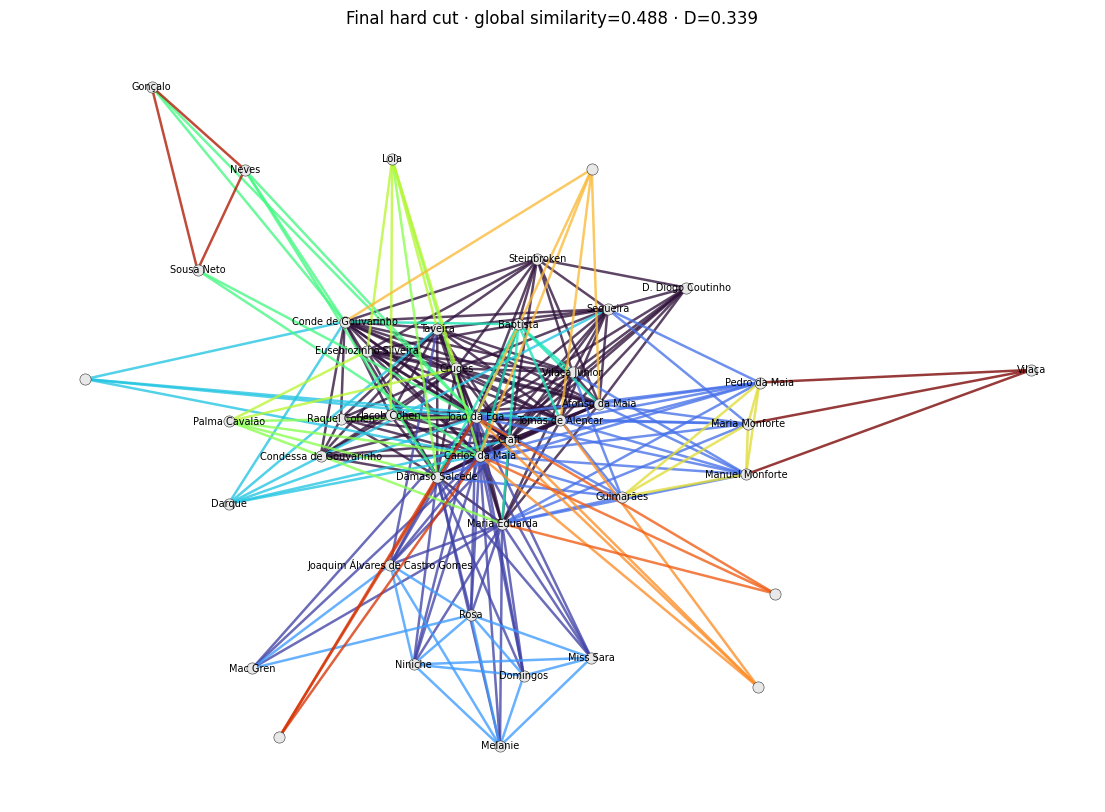

In [8]:
def plot_link_partition(graph, partition_result, title, seed=42):
    """Draw every reported link community; overlap nodes are labelled."""
    groups = partition_result["communities"]
    edges = set().union(*groups) if groups else set()
    view = graph.edge_subgraph(edges).copy()
    if view.number_of_edges() == 0:
        print("No reported communities to draw at this minimum community size.")
        return
    pos = nx.spring_layout(view, seed=seed, weight="weight", k=0.65, iterations=100)
    palette = plt.cm.get_cmap("turbo", max(1, len(groups)))
    fig, ax = plt.subplots(figsize=(14, 10))
    for community_id, group in enumerate(groups):
        nx.draw_networkx_edges(
            view, pos, edgelist=list(group), edge_color=[palette(community_id)],
            width=1.8, alpha=.78, ax=ax,
        )
    nx.draw_networkx_nodes(
        view, pos, node_size=65, node_color="#e8e8e8",
        edgecolors="#333333", linewidths=.4, ax=ax,
    )
    labels = {
        node: name_map.get(node, node) for node in view
        if len(partition_result["membership"].get(node, [])) > 1 or graph.degree(node) >= 8
    }
    nx.draw_networkx_labels(view, pos, labels=labels, font_size=7, ax=ax)
    ax.set_title(title)
    ax.axis("off")
    plt.show()


plot_link_partition(
    H, result,
    f"Final hard cut · global similarity={result['best_similarity']:.3f} · D={result['best_D']:.3f}",
)


## 9. Adaptive cut — branch-specific dendrogram heights

The hard cut forces every branch to stop at one global similarity. Here, each walk starts from that cut and proposes local branch moves: a community can be split into its two children or merged upward with its neighbouring branch. A Metropolis–Hastings rule occasionally accepts a lower-density move while the walk cools, then retains the best partition found. This is stochastic, so five fixed seeds are shown before choosing the highest-density reproducible run.

Unlike a node partition, both results below still permit a character to appear in several link communities.


In [9]:
ADAPTIVE_SEEDS = (2026, 2027, 2028, 2029, 2030)
ADAPTIVE_STEPS = 5_000

# Each walk starts at the hard cut, then moves a branch up or down in the
# dendrogram. Retaining the best state makes the reported result at least as
# good as that walk's starting point. The seed list keeps the stochastic search
# reproducible and exposes its run-to-run variation.
adaptive_walks = [
    run_adaptive_walk(result, seed=seed, n_steps=ADAPTIVE_STEPS)
    for seed in ADAPTIVE_SEEDS
]
adaptive_runs = pd.DataFrame([{
    "seed": walk["seed"],
    "D_adaptive": walk["best_D"],
    "D_gain_over_hard": walk["best_D"] - result["best_D"],
    "proposals": walk["n_proposed"],
    "accepted": walk["n_accepted"],
    "acceptance_rate": walk["acceptance_rate"],
    "temperature": walk["temperature"],
} for walk in adaptive_walks]).sort_values(["D_adaptive", "seed"], ascending=[False, True])
adaptive_walk = min(adaptive_walks, key=lambda walk: (-walk["best_D"], walk["seed"]))
adaptive_result = adaptive_walk["best_partition"]

adaptive_community_summary = link_community_summary(adaptive_result, name_map)
adaptive_membership = link_membership_table(adaptive_result, name_map)
if not adaptive_membership.empty:
    adaptive_membership["degree_in_threshold_graph"] = adaptive_membership["character_id"].map(degree_map)

cut_comparison = pd.DataFrame([
    {
        "cut": "Hard: one global height",
        "partition_density_D": result["best_D"],
        "reported_communities": len(result["communities"]),
        "links_in_reported_communities": sum(map(len, result["communities"])),
    },
    {
        "cut": f"Adaptive: best of {len(ADAPTIVE_SEEDS)} walks (seed {adaptive_walk['seed']})",
        "partition_density_D": adaptive_result["best_D"],
        "reported_communities": len(adaptive_result["communities"]),
        "links_in_reported_communities": sum(map(len, adaptive_result["communities"])),
    },
])

display(adaptive_runs.reset_index(drop=True).round(5))
display(cut_comparison.round(4))
print(f"Adaptive cut selected seed={adaptive_walk['seed']}; D={adaptive_result['best_D']:.4f}")
display(adaptive_community_summary)
display(adaptive_membership.sort_values(["community", "character"]).reset_index(drop=True))

adaptive_overlap_table = (
    adaptive_membership[adaptive_membership["is_overlap"]]
    .groupby(["character_id", "character"])["community"]
    .agg(list).reset_index().sort_values("character")
) if not adaptive_membership.empty else pd.DataFrame()
print("Characters whose incident links span multiple reported adaptive communities:")
display(adaptive_overlap_table)


,seed,D_adaptive,D_gain_over_hard,proposals,accepted,acceptance_rate,temperature
0,2026,0.36466,0.0253,5000,2099,0.4198,0.00029
1,2027,0.36466,0.0253,5000,2009,0.4018,0.00029
2,2028,0.36466,0.0253,5000,2005,0.4010,0.00029
3,2029,0.36466,0.0253,5000,1988,0.3976,0.00029
4,2030,0.36466,0.0253,5000,1997,0.3994,0.00029


,cut,partition_density_D,reported_communities,links_in_reported_communities
0,Hard: one global height,0.3394,16,247
1,Adaptive: best of 5 walks (seed 2026),0.3647,27,306


Adaptive cut selected seed=2026; D=0.3647


,community,links,characters,members
0,1,115,18,"Afonso da Maia, Carlos da Maia, Conde de Gouva..."
1,2,28,13,"Carlos da Maia, Craft, Domingos, Dâmaso Salced..."
2,3,23,11,"Afonso da Maia, Carlos da Maia, Dâmaso Salcede..."
3,4,16,12,"abade Custódio, Afonso da Maia, Brown, Carlos ..."
4,5,13,6,"Domingos, Joaquim Álvares de Castro Gomes, Mel..."
5,6,9,8,"abade Custódio, Brown, D. Ana Silveira, D. Eug..."
6,7,8,9,"Afonso da Maia, Baptista, Carlos da Maia, Cond..."
7,8,7,8,"Afonso da Maia, Carlos da Maia, Conde de Gouva..."
8,9,7,7,"Carlos da Maia, Conde de Gouvarinho, Dâmaso Sa..."
9,10,6,7,"Augusta, Carlos da Maia, Encarnación, Mendonça..."


,community,character_id,character,is_overlap,degree_in_threshold_graph
0,1,afonso_maia,Afonso da Maia,True,32
1,1,carlos_maia,Carlos da Maia,True,62
2,1,conde_gouvarinho,Conde de Gouvarinho,True,20
3,1,condessa_gouvarinho,Condessa de Gouvarinho,True,14
4,1,craft,Craft,True,22
...,...,...,...,...,...
176,26,teles_gama,Teles da Gama,True,7
177,26,vladimiro,Vladimiro,False,4
178,27,gonçalo,Gonçalo,True,4
179,27,neves,Neves,True,6


Characters whose incident links span multiple reported adaptive communities:


,character_id,character,community
1,afonso_maia,Afonso da Maia,"[1, 3, 4, 7, 8, 13, 19]"
3,baptista,Baptista,"[7, 14]"
4,brown,Brown,"[4, 6]"
5,carlos_maia,Carlos da Maia,"[1, 2, 3, 4, 7, 8, 9, 10, 13, 14, 15, 16, 17, ..."
6,conde_gouvarinho,Conde de Gouvarinho,"[1, 7, 8, 9, 18]"
7,condessa_gouvarinho,Condessa de Gouvarinho,"[1, 15]"
8,craft,Craft,"[1, 2, 17, 18, 20]"
9,cruges,Cruges,"[1, 11, 22]"
2,ana_silveira,D. Ana Silveira,"[4, 6]"
13,eugenia_silveira,D. Eugénia Silveira,"[4, 6]"


### Final adaptive-cut network view

This uses the same graph and layout rule as the hard-cut figure, so the branch-specific result can be compared directly.


C:\Users\lenovo\AppData\Local\Temp\ipykernel_42160\626484920.py:10: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette = plt.cm.get_cmap("turbo", max(1, len(groups)))


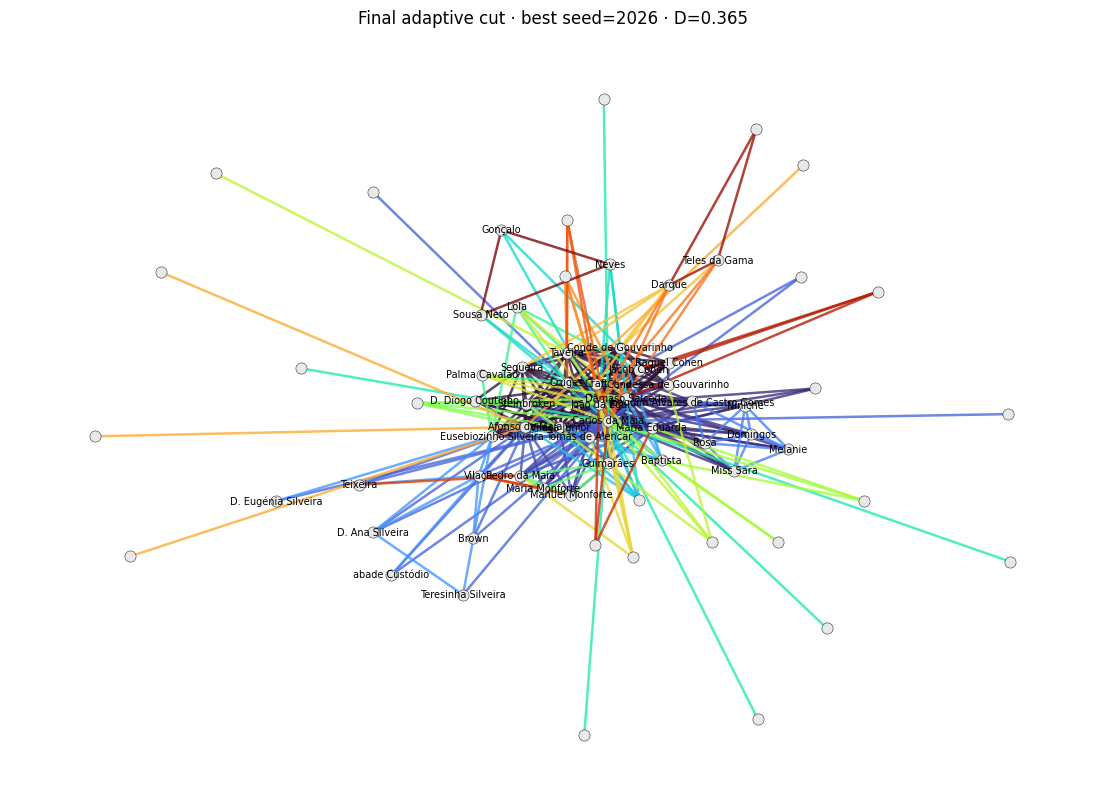

In [10]:
plot_link_partition(
    H, adaptive_result,
    f"Final adaptive cut · best seed={adaptive_walk['seed']} · D={adaptive_result['best_D']:.3f}",
)


## 10. Hub-pruned link communities — restore hubs as bridges

Hubs can make a dense link community look larger than the context it represents. This optional robustness check removes high-degree characters before clustering the remaining core. It then restores every removed incident link as a dashed **bridge**: the hub can connect several core communities, but is not forced into any one of them.

The default identifies the top 5% of degrees (with a minimum degree of 4). Change `HUB_NODES` to choose the characters explicitly, or adjust the two settings. This is a visualization and sensitivity analysis, not a replacement for the full link-community result above.


In [27]:
# Choose hubs from the thresholded graph, or replace None with explicit IDs,
# for example: HUB_NODES = ["joao_ega", "carlos_maia"].
HUB_NODES = None
HUB_TOP_FRACTION = 0.05
HUB_MIN_DEGREE = 4

degree_map = dict(H.degree())
if HUB_NODES is None:
    ranked_degrees = sorted(degree_map.values(), reverse=True)
    rank = max(1, math.ceil(len(ranked_degrees) * HUB_TOP_FRACTION))
    degree_cutoff = max(HUB_MIN_DEGREE, ranked_degrees[rank - 1]) if ranked_degrees else np.inf
    hub_nodes = sorted(node for node, degree in degree_map.items() if degree >= degree_cutoff)
else:
    hub_nodes = sorted(set(HUB_NODES) & set(H))
    degree_cutoff = min((degree_map[node] for node in hub_nodes), default=np.nan)

hub_table = pd.DataFrame([
    {"character_id": node, "character": name_map.get(node, node), "degree": degree_map[node]}
    for node in hub_nodes
]).sort_values("degree", ascending=False) if hub_nodes else pd.DataFrame(
    columns=["character_id", "character", "degree"]
)

H_core = H.copy()
H_core.remove_nodes_from(hub_nodes)
hub_core_result = link_communities(H_core, min_community_links=MIN_COMMUNITY_LINKS)
hub_core_summary = link_community_summary(hub_core_result, name_map)
hub_core_membership = link_membership_table(hub_core_result, name_map)
if not hub_core_membership.empty:
    hub_core_membership["degree_in_threshold_graph"] = hub_core_membership["character_id"].map(degree_map)

bridge_rows = []
for u, v, data in H.edges(data=True):
    if u not in hub_nodes and v not in hub_nodes:
        continue
    hubs_on_edge = [node for node in (u, v) if node in hub_nodes]
    non_hub = v if u in hub_nodes and v not in hub_nodes else u if v in hub_nodes and u not in hub_nodes else None
    target_communities = hub_core_result["membership"].get(non_hub, []) if non_hub is not None else []
    for hub in hubs_on_edge:
        bridge_rows.append({
            "hub_id": hub,
            "hub": name_map.get(hub, hub),
            "neighbor_id": non_hub,
            "neighbor": name_map.get(non_hub, non_hub) if non_hub is not None else "another removed hub",
            "weight": data.get("weight", 1.0),
            "core_communities_reached": ", ".join(f"C{community}" for community in target_communities) or "none",
        })
hub_bridge_table = pd.DataFrame(bridge_rows)
hub_bridge_summary = (
    hub_bridge_table.groupby(["hub_id", "hub"], as_index=False)
    .agg(bridge_links=("neighbor", "size"),
         core_communities_reached=("core_communities_reached", lambda values: ", ".join(sorted({value for value in values if value != "none"}))))
    .sort_values("bridge_links", ascending=False)
) if not hub_bridge_table.empty else pd.DataFrame(
    columns=["hub_id", "hub", "bridge_links", "core_communities_reached"]
)

print(f"Removed {len(hub_nodes)} hub(s) using degree cutoff ≥ {degree_cutoff}; core has {H_core.number_of_nodes()} nodes and {H_core.number_of_edges()} links.")
display(hub_table)
display(hub_core_summary)
display(hub_core_membership.sort_values(["community", "character"]).reset_index(drop=True))
print("Restored hub links are bridges, not community memberships:")
display(hub_bridge_summary)
display(hub_bridge_table.sort_values(["hub", "neighbor"]).reset_index(drop=True))


Removed 6 hub(s) using degree cutoff ≥ 23; core has 97 nodes and 145 links.


,character_id,character,degree
1,carlos_maia,Carlos da Maia,62
3,joao_ega,João da Ega,42
0,afonso_maia,Afonso da Maia,32
2,damaso_salcede,Dâmaso Salcede,29
5,tomas_alencar,Tomás de Alencar,25
4,maria_eduarda,Maria Eduarda,23


,community,links,characters,members
0,1,41,11,"Conde de Gouvarinho, Condessa de Gouvarinho, C..."
1,2,13,6,"Domingos, Joaquim Álvares de Castro Gomes, Mel..."
2,3,6,6,"Cruges, Eusebiozinho Silveira, Jacob Cohen, Lo..."
3,4,6,4,"Guimarães, Manuel Monforte, Maria Monforte, Pe..."
4,5,5,6,"Conde de Gouvarinho, Craft, Darque, Sequeira, ..."
5,6,4,5,"Craft, D. Diogo Coutinho, Sequeira, Steinbroke..."
6,7,3,3,"Darque, Teles da Gama, Vladimiro"
7,8,3,3,"Gonçalo, Neves, Sousa Neto"
8,9,3,4,"Manuel Monforte, Maria Monforte, Pedro da Maia..."


,community,character_id,character,is_overlap,degree_in_threshold_graph
0,1,conde_gouvarinho,Conde de Gouvarinho,True,20
1,1,condessa_gouvarinho,Condessa de Gouvarinho,False,14
2,1,craft,Craft,True,22
3,1,cruges,Cruges,True,19
4,1,eusebiozinho_silveira,Eusebiozinho Silveira,True,16
5,1,jacob_cohen,Jacob Cohen,True,13
6,1,raquel_cohen,Raquel Cohen,False,11
7,1,sequeira,Sequeira,True,15
8,1,steinbroken,Steinbroken,True,14
9,1,taveira,Taveira,True,21


Restored hub links are bridges, not community memberships:


,hub_id,hub,bridge_links,core_communities_reached
1,carlos_maia,Carlos da Maia,62,"C1, C1, C3, C1, C3, C5, C1, C5, C1, C5, C6, C1..."
3,joao_ega,João da Ega,42,"C1, C1, C3, C1, C3, C5, C1, C5, C1, C5, C6, C1..."
0,afonso_maia,Afonso da Maia,32,"C1, C3, C1, C3, C5, C1, C5, C1, C5, C6, C1, C6..."
2,damaso_salcede,Dâmaso Salcede,29,"C1, C1, C3, C1, C3, C5, C1, C5, C1, C5, C6, C2..."
5,tomas_alencar,Tomás de Alencar,25,"C1, C1, C3, C1, C3, C5, C1, C5, C1, C5, C6, C1..."
4,maria_eduarda,Maria Eduarda,23,"C1, C3, C1, C5, C6, C1, C6, C2, C3, C4, C4, C9"


,hub_id,hub,neighbor_id,neighbor,weight,core_communities_reached
0,afonso_maia,Afonso da Maia,andre_ega,André da Ega,3.0,none
1,afonso_maia,Afonso da Maia,baptista,Baptista,5.0,none
2,afonso_maia,Afonso da Maia,brown,Brown,5.0,none
3,afonso_maia,Afonso da Maia,conde_gouvarinho,Conde de Gouvarinho,4.0,"C1, C5"
4,afonso_maia,Afonso da Maia,conde_runa,Conde de Runa,3.0,none
...,...,...,...,...,...,...
208,tomas_alencar,Tomás de Alencar,None,another removed hub,71.0,none
209,tomas_alencar,Tomás de Alencar,None,another removed hub,56.0,none
210,tomas_alencar,Tomás de Alencar,None,another removed hub,4.0,none
211,tomas_alencar,Tomás de Alencar,None,another removed hub,16.0,none


### Hub-pruned core with restored bridges

Coloured edges were clustered after the hubs were removed. Dashed dark edges are the original links restored afterward; square red nodes are the removed hubs. A hub therefore remains visible as a bridge without acquiring a misleading exclusive community label.


C:\Users\lenovo\AppData\Local\Temp\ipykernel_42160\203820638.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  palette = plt.cm.get_cmap("turbo", max(1, len(groups)))


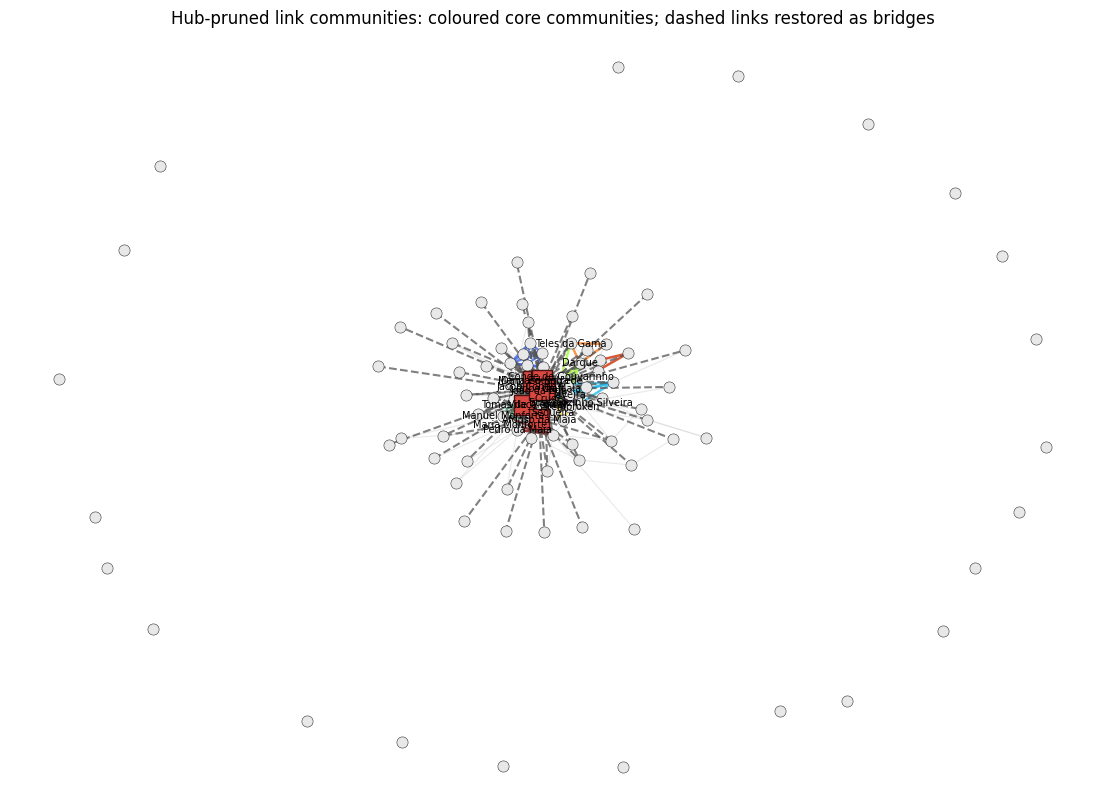

In [28]:
def plot_hub_pruned_link_communities(graph, hubs, core_result, title, seed=42):
    """Color core link communities and restore every removed-hub link as a bridge."""
    pos = nx.spring_layout(graph, seed=seed, weight="weight", k=0.75, iterations=120)
    groups = core_result["communities"]
    palette = plt.cm.get_cmap("turbo", max(1, len(groups)))
    bridge_edges = [(u, v) for u, v in graph.edges() if u in hubs or v in hubs]
    core_unreported_edges = [
        (u, v) for u, v in graph.edges()
        if u not in hubs and v not in hubs and not any((u, v) in group or (v, u) in group for group in groups)
    ]

    fig, ax = plt.subplots(figsize=(14, 10))
    nx.draw_networkx_edges(graph, pos, edgelist=core_unreported_edges, edge_color="#d0d0d0", width=.8, alpha=.45, ax=ax)
    for community_id, group in enumerate(groups):
        nx.draw_networkx_edges(graph, pos, edgelist=list(group), edge_color=[palette(community_id)], width=1.8, alpha=.8, ax=ax)
    nx.draw_networkx_edges(graph, pos, edgelist=bridge_edges, edge_color="#555555", style="dashed", width=1.5, alpha=.75, ax=ax)

    core_nodes = [node for node in graph if node not in hubs]
    nx.draw_networkx_nodes(graph, pos, nodelist=core_nodes, node_size=65, node_color="#e8e8e8", edgecolors="#333333", linewidths=.4, ax=ax)
    nx.draw_networkx_nodes(graph, pos, nodelist=list(hubs), node_size=220, node_color="#d94841", node_shape="s", edgecolors="#4a1111", linewidths=1.0, ax=ax)
    labels = {node: name_map.get(node, node) for node in hubs}
    labels.update({
        node: name_map.get(node, node) for node in core_nodes
        if len(core_result["membership"].get(node, [])) > 1
    })
    nx.draw_networkx_labels(graph, pos, labels=labels, font_size=7, ax=ax)
    ax.set_title(title)
    ax.axis("off")
    plt.show()


plot_hub_pruned_link_communities(
    H, set(hub_nodes), hub_core_result,
    "Hub-pruned link communities: coloured core communities; dashed links restored as bridges",
)


## 11. Optional degree-preserving null model

The observed maximum partition density can be compared with networks that preserve the degree sequence but randomize which characters are connected. This is computationally more expensive because link similarities and the full hierarchy must be recomputed for every randomized graph.

Start with 20 null replicates for a first check; increase to 100 or more for a more precise tail estimate. The empirical upper-tail p-value uses the standard +1 correction.

Observed D*=0.3394
Null mean=0.2115; SD=0.0239; upper-tail p=0.0476


,replicate,D_star_null,communities_null
count,20.0000,20.0000,20.0000
mean,9.5000,0.2115,16.3000
std,5.9161,0.0245,5.1309
min,0.0000,0.1531,3.0000
25%,4.7500,0.1984,12.0000
50%,9.5000,0.2118,17.5000
75%,14.2500,0.2335,20.0000
max,19.0000,0.2451,24.0000


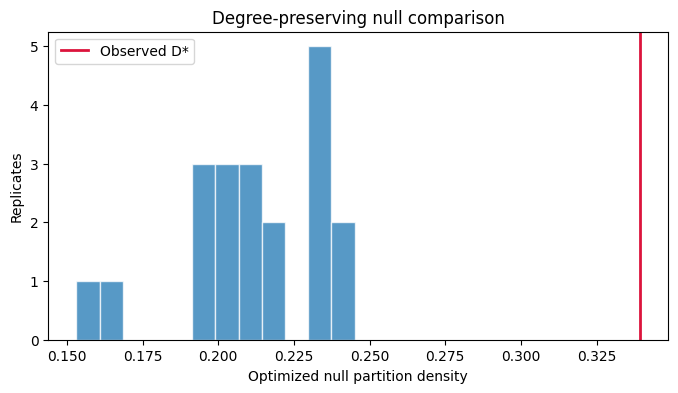

In [29]:
N_NULL = 20  # set to 0 to skip; increase for a more precise null distribution
NULL_SEED = 4200
null_rows = []

if N_NULL > 0:
    for replicate in range(N_NULL):
        rng_seed = NULL_SEED + 100_000 * W_MIN + replicate
        null_graph = nx.Graph()
        null_graph.add_nodes_from(H.nodes())
        null_graph.add_edges_from(H.edges())
        m = null_graph.number_of_edges()
        if m < 2:
            continue
        try:
            nx.double_edge_swap(
                null_graph, nswap=10*m, max_tries=100*m,
                seed=rng_seed
            )
        except nx.NetworkXAlgorithmError:
            warnings.warn(f"Could not complete degree-preserving swaps for replicate {replicate}")
            continue
        null_result = link_communities(
            null_graph, min_community_links=MIN_COMMUNITY_LINKS
        )
        null_rows.append({
            "replicate": replicate,
            "D_star_null": null_result["best_D"],
            "communities_null": len(null_result["communities"]),
        })

null_df = pd.DataFrame(null_rows)
if not null_df.empty:
    observed_D = result["best_D"]
    p_upper = (1 + int((null_df["D_star_null"] >= observed_D).sum())) / (len(null_df)+1)
    print(f"Observed D*={observed_D:.4f}")
    print(f"Null mean={null_df['D_star_null'].mean():.4f}; "
          f"SD={null_df['D_star_null'].std(ddof=0):.4f}; "
          f"upper-tail p={p_upper:.4f}")
    display(null_df.describe().round(4))
    fig, ax = plt.subplots(figsize=(8,4))
    ax.hist(null_df["D_star_null"], bins=12, alpha=.75, edgecolor="white")
    ax.axvline(observed_D, color="crimson", linewidth=2, label="Observed D*")
    ax.set_xlabel("Optimized null partition density")
    ax.set_ylabel("Replicates")
    ax.legend()
    ax.set_title("Degree-preserving null comparison")
    plt.show()
else:
    print("Null model skipped or produced no valid replicates.")

## 12. Export results

In [30]:
OUTPUT_DIR = Path.cwd() / "link_communities_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)
summary.to_csv(OUTPUT_DIR / "link_communities_threshold_summary.csv", index=False)
community_summary.to_csv(OUTPUT_DIR / f"link_communities_w{W_MIN}_communities.csv", index=False)
membership.to_csv(OUTPUT_DIR / f"link_communities_w{W_MIN}_memberships.csv", index=False)
result["merges"].to_csv(OUTPUT_DIR / f"link_communities_w{W_MIN}_merge_log.csv", index=False)
result["density_curve"].to_csv(OUTPUT_DIR / f"link_communities_w{W_MIN}_density_curve.csv", index=False)
if not null_df.empty:
    null_df.to_csv(OUTPUT_DIR / f"link_communities_w{W_MIN}_null.csv", index=False)
adaptive_runs.to_csv(OUTPUT_DIR / f"link_communities_w{W_MIN}_adaptive_runs.csv", index=False)
cut_comparison.to_csv(OUTPUT_DIR / f"link_communities_w{W_MIN}_cut_comparison.csv", index=False)
adaptive_community_summary.to_csv(OUTPUT_DIR / f"link_communities_w{W_MIN}_adaptive_communities.csv", index=False)
adaptive_membership.to_csv(OUTPUT_DIR / f"link_communities_w{W_MIN}_adaptive_memberships.csv", index=False)
hub_table.to_csv(OUTPUT_DIR / f"link_communities_w{W_MIN}_removed_hubs.csv", index=False)
hub_core_summary.to_csv(OUTPUT_DIR / f"link_communities_w{W_MIN}_hub_pruned_communities.csv", index=False)
hub_core_membership.to_csv(OUTPUT_DIR / f"link_communities_w{W_MIN}_hub_pruned_memberships.csv", index=False)
hub_bridge_table.to_csv(OUTPUT_DIR / f"link_communities_w{W_MIN}_hub_bridges.csv", index=False)
print("Saved outputs to:", OUTPUT_DIR.resolve())

Saved outputs to: C:\Users\lenovo\OneDrive\Documentos\Uni\DTU - Master in Business Analytics\Social Graphs\SGI-Project\link_communities_outputs


In [31]:
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(hub_core_membership)

,community,character_id,character,is_overlap,degree_in_threshold_graph
0,1,conde_gouvarinho,Conde de Gouvarinho,True,20
1,1,condessa_gouvarinho,Condessa de Gouvarinho,False,14
2,1,craft,Craft,True,22
3,1,cruges,Cruges,True,19
4,1,eusebiozinho_silveira,Eusebiozinho Silveira,True,16
5,1,jacob_cohen,Jacob Cohen,True,13
6,1,raquel_cohen,Raquel Cohen,False,11
7,1,sequeira,Sequeira,True,15
8,1,steinbroken,Steinbroken,True,14
9,1,taveira,Taveira,True,21


In [ ]:
with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
    display(hub_core_summary[hub_core_summary['characters'] > ])

# alta sociedade
# maria eduarda 
# cohen 


,community,links,characters,members
0,1,41,11,"Conde de Gouvarinho, Condessa de Gouvarinho, Craft, Cruges, Eusebiozinho Silveira, Jacob Cohen, Raquel Cohen, Sequeira, Steinbroken, Taveira, Vilaça Júnior"
1,2,13,6,"Domingos, Joaquim Álvares de Castro Gomes, Melanie, Miss Sara, Niniche, Rosa"
2,3,6,6,"Cruges, Eusebiozinho Silveira, Jacob Cohen, Lola, Palma Cavalão, Taveira"
3,4,6,4,"Guimarães, Manuel Monforte, Maria Monforte, Pedro da Maia"
4,5,5,6,"Conde de Gouvarinho, Craft, Darque, Sequeira, Taveira, Teles da Gama"
5,6,4,5,"Craft, D. Diogo Coutinho, Sequeira, Steinbroken, Vilaça Júnior"
6,7,3,3,"Darque, Teles da Gama, Vladimiro"
7,8,3,3,"Gonçalo, Neves, Sousa Neto"
8,9,3,4,"Manuel Monforte, Maria Monforte, Pedro da Maia, Vilaça"


In [33]:
core_characters_by_community = (
    hub_core_membership.groupby("community")["character"]
    .agg(set)
    .to_dict()
)

hubs_by_community = {}
for row in hub_bridge_table.itertuples(index=False):
    for label in str(row.core_communities_reached).split(","):
        label = label.strip()
        if label.startswith("C") and label[1:].isdigit():
            community_id = int(label[1:])
            hubs_by_community.setdefault(community_id, set()).add(row.hub)

communities_with_hubs = pd.DataFrame(
    [
        {
            "community_id": community_id,
            "characters": ", ".join(sorted(
                core_characters_by_community.get(community_id, set()) | hubs,
                key=str.casefold,
            )),
        }
        for community_id, hubs in sorted(hubs_by_community.items())
    ],
    columns=["community_id", "characters"],
)

display(communities_with_hubs)

,community_id,characters
0,1,"Afonso da Maia, Carlos da Maia, Conde de Gouva..."
1,2,"Carlos da Maia, Domingos, Dâmaso Salcede, Joaq..."
2,3,"Afonso da Maia, Carlos da Maia, Cruges, Dâmaso..."
3,4,"Afonso da Maia, Carlos da Maia, Dâmaso Salcede..."
4,5,"Afonso da Maia, Carlos da Maia, Conde de Gouva..."
5,6,"Afonso da Maia, Carlos da Maia, Craft, D. Diog..."
6,7,"Carlos da Maia, Darque, João da Ega, Teles da ..."
7,8,"Carlos da Maia, Dâmaso Salcede, Gonçalo, João ..."
8,9,"Afonso da Maia, Carlos da Maia, Dâmaso Salcede..."


## 13. Interpretation and limitations

- Link communities group **relationships**, not characters directly. Character communities are induced from the links incident to each cluster.
- A character may belong to several communities. This is a feature of the method, not an error.
- The method can detect sparse contexts that k-clique percolation misses, because it does not require a complete clique.
- The maximum partition density is a structural objective, not a probability that the communities are narratively correct.
- The reported minimum of three links is a reporting convention. Tiny components remain in `all_groups` and are excluded from the character-membership table.
- Validate the most interesting communities against the relevant passages in *Os Maias*. Co-occurrence alone does not establish a social relationship.